# 1. Khởi tạo môi trường & Đọc dữ liệu

In [1]:

# export
import re
import unicodedata
import pandas as pd

from helpers.get_configs import get_config

RAW_DATA_PATH = get_config('dirs.yaml', ['raw_data', 'cutoff_scores'], as_path=True)
CLEANED_DATA_PATH = get_config('dirs.yaml', ['cleaned_data', 'cutoff_scores'], as_path=True)
CLEANED_BLOCKS_PATH = get_config('dirs.yaml', ['cleaned_data', 'score_blocks'], as_path=True)
CLEANED_MAJORS_PATH = get_config('dirs.yaml', ['cleaned_data', 'majors'], as_path=True)
SCRIPT_OUTPUT_PATH = get_config('dirs.yaml', ['unit_scripts', 'cutoff_scores'], as_path=True)

# Đọc file CSV vào DataFrame
df = pd.read_csv(RAW_DATA_PATH, encoding='utf-8')


In [2]:
# Khảo sát thông tin tổng quan của dataset
df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 147671 entries, 0 to 147670
Data columns (total 15 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   school_id                 147671 non-null  str    
 1   school_name               147671 non-null  str    
 2   school_type               147671 non-null  str    
 3   school_short_name         138565 non-null  str    
 4   province_id               147671 non-null  int64  
 5   province_name             147671 non-null  str    
 6   score_code                145478 non-null  str    
 7   score_name                147088 non-null  str    
 8   score_blocks              118135 non-null  str    
 9   score_mark                145686 non-null  float64
 10  score_year                143459 non-null  float64
 11  score_introtext           33581 non-null   str    
 12  score_formula             32022 non-null   str    
 13  score_is_converted_score  147513 non-null  float64
 14 

,school_id,school_name,school_type,school_short_name,province_id,province_name,score_code,score_name,score_blocks,score_mark,score_year,score_introtext,score_formula,score_is_converted_score,score_admission_name
0,CDD0209,Trường Cao Đẳng Sài Gòn,Cao đẳng,NaN,23,TP Hồ Chí Minh,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,CDT026,Trường Cao đẳng Giao thông vận tải trung ương VI,Cao đẳng,NaN,23,TP Hồ Chí Minh,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,CDD0229,Trường Cao đẳng Bách khoa Nam Sài Gòn,Cao đẳng,NaN,23,TP Hồ Chí Minh,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,CDD0410,Trường Cao Đẳng Công Nghệ Ngoại Thương,Cao đẳng,NaN,23,TP Hồ Chí Minh,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,CDT0218,Trường Cao đẳng Thủ Thiêm – TP. Hồ Chí Minh,Cao đẳng,NaN,23,TP Hồ Chí Minh,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# 2. Loại bỏ cột không dùng

In [3]:
# export
df.drop(columns=['score_formula', 'score_is_converted_score'], inplace=True)

# 3. Kiểm tra và xử lý giá trị rỗng

In [4]:
# export
df.dropna(subset=['score_code', 'score_name', 'score_mark', 'score_year', 'score_admission_name', 'province_id', 'province_name'], inplace=True)

In [5]:
# Khảo sát dữ liệu sau dropna
df.info()
df.isna().sum()

<class 'pandas.DataFrame'>
Index: 141825 entries, 6 to 147670
Data columns (total 13 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   school_id             141825 non-null  str    
 1   school_name           141825 non-null  str    
 2   school_type           141825 non-null  str    
 3   school_short_name     133352 non-null  str    
 4   province_id           141825 non-null  int64  
 5   province_name         141825 non-null  str    
 6   score_code            141825 non-null  str    
 7   score_name            141825 non-null  str    
 8   score_blocks          115280 non-null  str    
 9   score_mark            141825 non-null  float64
 10  score_year            141825 non-null  float64
 11  score_introtext       32103 non-null   str    
 12  score_admission_name  141825 non-null  str    
dtypes: float64(2), int64(1), str(10)
memory usage: 35.6 MB


school_id                    0
school_name                  0
school_type                  0
school_short_name         8473
province_id                  0
province_name                0
score_code                   0
score_name                   0
score_blocks             26545
score_mark                   0
score_year                   0
score_introtext         109722
score_admission_name         0
dtype: int64

# 4. Chuẩn hóa dữ liệu

## 4.1. Chuẩn hóa danh sách và chuỗi

In [6]:
# export
def remove_newlines(val):
    if pd.isna(val):
        return val
    if isinstance(val, str):
        return re.sub(r'[\r\n]+', ' ', val).strip()
    return val

df = df.map(remove_newlines)

def normalize_score_blocks(val):
    if pd.isna(val) or str(val).strip() == '':
        return val
    s = str(val).replace(',', ';')      # thay dấu ',' thành ';'
    s = re.sub(r'\s+', '', s)           # loại bỏ mọi khoảng trắng (space, tab, \n, ...)
    return s

df['score_blocks'] = df['score_blocks'].apply(normalize_score_blocks)

## 4.2. Giới hạn phạm vi nghiên cứu

In [7]:
# export
# Ép kiểu score_year về int64
df['score_year'] = df['score_year'].astype('int64')

# Loại bỏ các score_year < 2010 và > 2025
df = df[(df['score_year'] >= 2010) & (df['score_year'] <= 2025)]

# Loại bỏ các score_mark <= 0
df = df[(df['score_year'] > 0)]

In [8]:
# Khảo sát dữ liệu sau lọc năm
df.info()
df.isna().sum()

<class 'pandas.DataFrame'>
Index: 133660 entries, 6 to 147670
Data columns (total 13 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   school_id             133660 non-null  str    
 1   school_name           133660 non-null  str    
 2   school_type           133660 non-null  str    
 3   school_short_name     125610 non-null  str    
 4   province_id           133660 non-null  int64  
 5   province_name         133660 non-null  str    
 6   score_code            133660 non-null  str    
 7   score_name            133660 non-null  str    
 8   score_blocks          109966 non-null  str    
 9   score_mark            133660 non-null  float64
 10  score_year            133660 non-null  int64  
 11  score_introtext       30655 non-null   str    
 12  score_admission_name  133660 non-null  str    
dtypes: float64(1), int64(2), str(10)
memory usage: 33.3 MB


school_id                    0
school_name                  0
school_type                  0
school_short_name         8050
province_id                  0
province_name                0
score_code                   0
score_name                   0
score_blocks             23694
score_mark                   0
score_year                   0
score_introtext         103005
score_admission_name         0
dtype: int64

## 4.3. Chuẩn hóa tên phương thức tuyển sinh

In [9]:
# export
mapping = {
    '��iểm thi THPT': 'Điểm thi THPT',
    'Điểm xét tốt nghiệp THPT': 'Điểm thi THPT',
    'Đi���m thi THPT': 'Điểm thi THPT',
    'Đi��m thi THPT': 'Điểm thi THPT',

    'Điểm h��c bạ': 'Điểm học bạ',
    'Điểm học b���': 'Điểm học bạ',

    '��iểm ĐGNL HSA': 'Điểm ĐGNL HSA',

    'Đi���m ĐGNL V-ACT': 'Điểm ĐGNL V-ACT',

    'Điểm xét tuyển kết h���p': 'Điểm xét tuyển kết hợp',
    'Điểm xét tuyển kết h��p': 'Điểm xét tuyển kết hợp',
    'Điểm x��t tuyển kết hợp': 'Điểm xét tuyển kết hợp',
    'Điểm xét tuyển k���t hợp': 'Điểm xét tuyển kết hợp',

    'Chứng chỉ qu��c tế': 'Chứng chỉ quốc tế',
    'Chứng chỉ quốc t���': 'Chứng chỉ quốc tế',
    'Chứng chỉ quốc t��': 'Chứng chỉ quốc tế',
}

df['score_admission_name'] = df['score_admission_name'].replace(mapping)

In [10]:
# Khảo sát phân phối tên phương thức sau chuẩn hóa
df['score_admission_name'].value_counts()

score_admission_name
Điểm thi THPT                  80006
Điểm học bạ                    24647
Điểm ĐGNL V-ACT                11571
Điểm ĐGNL HSA                   5250
Điểm ĐGTD TSA                   3168
Điểm xét tuyển kết hợp          3018
Chứng chỉ quốc tế               1593
ƯTXT, XT thẳng                  1340
Điểm Đánh giá đầu vào V-SAT     1270
Điểm ĐGNL SPT                   1202
Điểm thi riêng                   536
Điểm ĐGNL H-SCA                   35
Điểm ĐGNL SP2E                    24
Name: count, dtype: int64

## 4.4. Loại bỏ các dòng bị trùng

In [11]:
# export
df = df.drop_duplicates(
    subset=['school_id', 'score_code', 'score_blocks', 'score_mark', 'score_year', 'score_admission_name'],
    keep='first'
)

In [12]:
# Khảo sát số dòng sau khi loại bỏ trùng lặp
print(f"Số dòng sau khi loại bỏ trùng lặp: {len(df)}")

Số dòng sau khi loại bỏ trùng lặp: 131019


## 4.5. Chuẩn hóa điểm chuẩn (quy đổi thang 40 về thang 30)

In [13]:
# Khảo sát các hệ thống quy đổi khác nhau thông qua introtext
df['score_introtext'].unique().tolist()

[nan,
 'Xét điểm thi CĐ',
 'Xét điểm thi ĐH',
 'Môn Tiếng Anh nhân hệ số 2',
 'Tổng chỉ tiêu NVBS : 1000',
 'Môn Ngữ văn nhân hệ số 2',
 'Điểm chuẩn học bạ: 5.8',
 'Điểm chuẩn học bạ: 5.6',
 'Điểm chuẩn học bạ: 6.2',
 'Điểm chuẩn học bạ: 5.5',
 'Điểm chuẩn học bạ: 5.9',
 'Điểm chuẩn học bạ: 6.1',
 'Điểm chuẩn học bạ: 5.3',
 'Cao đẳng 2 năm, môn chuyên ngành (HS2): 7,5',
 'Cao đẳng 3 năm, môn chuyên ngành (HS2): 6,3',
 'Cao đẳng 3 năm, môn chuyên ngành (HS2): 8,0',
 'Cao đẳng 2 năm, môn chuyên ngành (HS2): 8,0',
 'Cao đẳng 2 năm, môn chuyên ngành (HS2): 7,0',
 'Cao đẳng 3 năm, môn chuyên ngành (HS2): 7,0',
 'KV3-HSPT',
 '12 điểm khối A TT ngành Mạng',
 '15 điểm TT ngành Du lịch',
 '11 điểm TT ngành Hoá học',
 '15 điểm TT ngành HD Du lịch',
 '12 điểm TT ngành Tự động',
 '15 điểm TT ngành Cơ-Đ tử',
 'Điểm trúng tuyển đợt 2: 15 điểm',
 'Tiếng anh nhân hệ số 2',
 'Tiếng Anh nhân hệ số 2',
 'Điểm trên áp dụng với với thí sinh KV3. Mức chênh lệch điểm trúng tuyển giữa các nhóm đối tượng liền 

In [14]:
# export
def normalize_text_unicode(text):
    """Chuẩn hóa text: bỏ dấu, viết thường, để so khớp không phụ thuộc dấu/hoa-thường"""
    if pd.isna(text):
        return ''
    text = str(text).lower()
    text = unicodedata.normalize('NFD', text)
    text = ''.join(c for c in text if unicodedata.category(c) != 'Mn')
    text = text.replace('đ', 'd')
    return text

keywords = ['thang 40', 'thang diem 40', 'he so 2', 'nhan 2']

def contains_thang40_keyword(text):
    norm_text = normalize_text_unicode(text)
    return any(kw in norm_text for kw in keywords)

mask_thang40 = df['score_introtext'].apply(contains_thang40_keyword)
df.loc[mask_thang40, 'score_mark'] = (
    df.loc[mask_thang40, 'score_mark'] / 40 * 30
)

In [15]:
# Khảo sát các dòng đã được quy đổi thang 40
print(f"Số dòng được quy đổi: {mask_thang40.sum()}")
df.loc[mask_thang40, ['score_introtext', 'score_mark']].head(10)

Số dòng được quy đổi: 2351


,score_introtext,score_mark
489,Môn Tiếng Anh nhân hệ số 2,9.9900
499,Môn Ngữ văn nhân hệ số 2,9.9900
1095,Tiếng anh nhân hệ số 2,12.0000
1098,Tiếng Anh nhân hệ số 2,12.9975
1356,nhân hệ số 2 môn năng khiếu,13.1250
1360,nhân hệ số 2 môn năng khiếu,18.3750
1364,nhân hệ số 2 môn năng khiếu,19.1250
1367,nhân hệ số 2 môn năng khiếu,20.2500
1705,Chuyên ngành nhân hệ số 2 >=8 điểm,12.3750
1709,Hình họa nhân hệ số 2 >=8 điểm,12.3750


## 4.6. Loại bỏ ngoại lai theo phương pháp IQR

In [16]:
# export
def remove_iqr_outliers(df, group_col='score_admission_name', value_col='score_mark'):
    """
    Áp dụng phương pháp IQR để loại bỏ ngoại lai trên value_col theo từng nhóm group_col.
    """
    groups = df[group_col].dropna().unique()
    keep_mask = pd.Series(True, index=df.index)

    for group in groups:
        group_idx = df.index[df[group_col] == group]
        subset = df.loc[group_idx, value_col].dropna()

        Q1 = subset.quantile(0.25)
        Q3 = subset.quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        subset_filtered = subset[(subset >= lower_bound) & (subset <= upper_bound)]
        outlier_idx = subset.index.difference(subset_filtered.index)
        keep_mask.loc[outlier_idx] = False

    return df.loc[keep_mask].reset_index(drop=True)

df = remove_iqr_outliers(df, group_col='score_admission_name', value_col='score_mark')

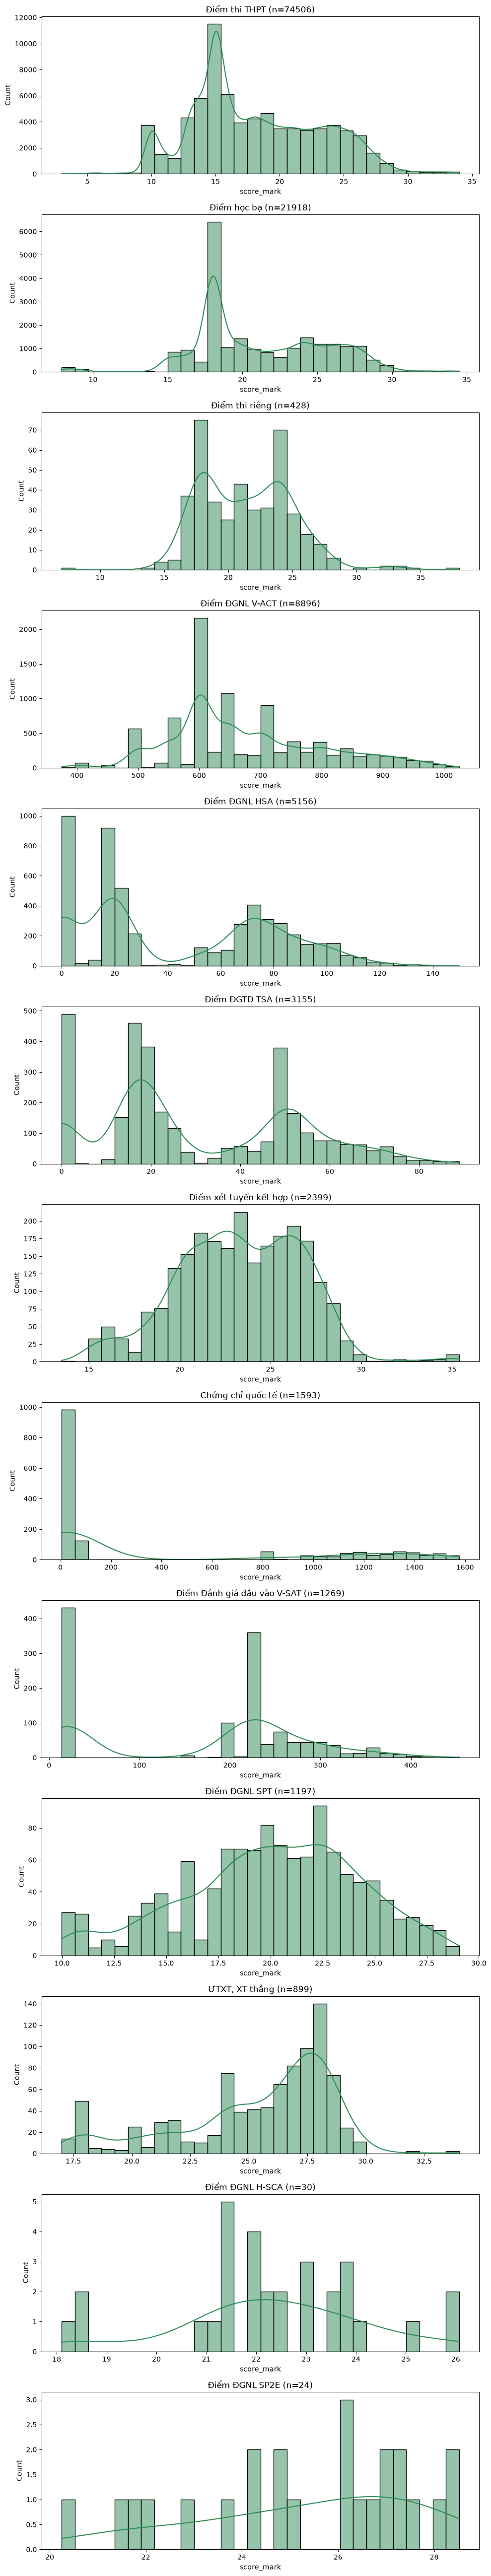

<class 'pandas.DataFrame'>
RangeIndex: 121470 entries, 0 to 121469
Data columns (total 13 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   school_id             121470 non-null  str    
 1   school_name           121470 non-null  str    
 2   school_type           121470 non-null  str    
 3   school_short_name     114492 non-null  str    
 4   province_id           121470 non-null  int64  
 5   province_name         121470 non-null  str    
 6   score_code            121470 non-null  str    
 7   score_name            121470 non-null  str    
 8   score_blocks          101441 non-null  str    
 9   score_mark            121470 non-null  float64
 10  score_year            121470 non-null  int64  
 11  score_introtext       26496 non-null   str    
 12  score_admission_name  121470 non-null  str    
dtypes: float64(1), int64(2), str(10)
memory usage: 29.2 MB


In [17]:
# Khảo sát trực quan hóa phân phối điểm sau lọc IQR
import matplotlib.pyplot as plt
import seaborn as sns

def plot_iqr_distributions(df, group_col='score_admission_name', value_col='score_mark'):
    groups = df[group_col].dropna().unique()
    n_groups = len(groups)
    fig, axes = plt.subplots(n_groups, 1, figsize=(10, 4 * n_groups))
    if n_groups == 1:
        axes = [axes]
    for i, group in enumerate(groups):
        subset = df[df[group_col] == group][value_col].dropna()
        sns.histplot(subset, kde=True, bins=30, ax=axes[i], color='seagreen')
        axes[i].set_title(f'{group} (n={len(subset)})')
        axes[i].set_xlabel(value_col)
        axes[i].set_ylabel('Count')
    plt.tight_layout()
    plt.show()

plot_iqr_distributions(df)
df.info()

## 4.7. Chuẩn hóa mã khối và mã ngành (khóa ngoại)

In [18]:
# export
df_blocks = pd.read_csv(CLEANED_BLOCKS_PATH, encoding='utf-8')
df_majors = pd.read_csv(CLEANED_MAJORS_PATH, encoding='utf-8')

valid_block_codes = set(df_blocks['code'].dropna().astype(str).str.strip())

major_score_codes_series = df_majors['score_codes'].dropna().astype(str)
valid_score_codes = set()
for val in major_score_codes_series:
    items = [x.strip() for x in val.split(';') if x.strip() != '']
    valid_score_codes.update(items)

def clean_score_blocks(val):
    if pd.isna(val) or str(val).strip() == '':
        return val
    items = [x.strip() for x in str(val).split(';') if x.strip() != '']
    kept = [x for x in items if x in valid_block_codes]
    return ';'.join(kept) if kept else pd.NA

df['score_blocks'] = df['score_blocks'].apply(clean_score_blocks)

def is_valid_score_code(val):
    if pd.isna(val) or str(val).strip() == '':
        return False
    code = str(val).strip()
    return code in valid_score_codes

mask_valid = df['score_code'].apply(is_valid_score_code)
df = df[mask_valid].reset_index(drop=True)

In [19]:
# Khảo sát dữ liệu sau khi validate khóa ngoại
df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 101466 entries, 0 to 101465
Data columns (total 13 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   school_id             101466 non-null  str    
 1   school_name           101466 non-null  str    
 2   school_type           101466 non-null  str    
 3   school_short_name     98561 non-null   str    
 4   province_id           101466 non-null  int64  
 5   province_name         101466 non-null  str    
 6   score_code            101466 non-null  str    
 7   score_name            101466 non-null  str    
 8   score_blocks          68998 non-null   str    
 9   score_mark            101466 non-null  float64
 10  score_year            101466 non-null  int64  
 11  score_introtext       20606 non-null   str    
 12  score_admission_name  101466 non-null  str    
dtypes: float64(1), int64(2), str(10)
memory usage: 24.2 MB


,school_id,school_name,school_type,school_short_name,province_id,province_name,score_code,score_name,score_blocks,score_mark,score_year,score_introtext,score_admission_name
0,CKC,Trường Cao Đẳng Kỹ Thuật Cao Thắng,Cao đẳng,NaN,23,TP Hồ Chí Minh,6510304,Công nghệ Kỹ thuật Cơ điện tử,A00;A01,16.00,2018,NaN,Điểm thi THPT
1,CKC,Trường Cao Đẳng Kỹ Thuật Cao Thắng,Cao đẳng,NaN,23,TP Hồ Chí Minh,6510304,Công nghệ Kỹ thuật Cơ điện tử (đạt chuẩn KOSEN...,A00;A01;A02;D01;D07;C01;C02,17.25,2025,Điểm chuẩn trúng tuyển (Toán nhân 2),Điểm học bạ
2,CKC,Trường Cao Đẳng Kỹ Thuật Cao Thắng,Cao đẳng,NaN,23,TP Hồ Chí Minh,6510304,Công nghệ Kỹ thuật Cơ điện tử (đạt chuẩn KOSEN...,A00;A01;A02;D01;D07;C01;C02,17.25,2025,Quy đổi thang điểm 30,Điểm học bạ
3,CKC,Trường Cao Đẳng Kỹ Thuật Cao Thắng,Cao đẳng,NaN,23,TP Hồ Chí Minh,6510304,Công nghệ Kỹ thuật Cơ điện tử (đạt chuẩn KOSEN...,NaN,500.00,2025,NaN,Điểm ĐGNL V-ACT
4,CES,Trường Cao Đẳng Công Thương TPHCM,Cao đẳng,NaN,23,TP Hồ Chí Minh,6510304,Công nghệ kỹ thuật cơ điện tử,NaN,13.00,2024,NaN,Điểm thi THPT


# 5. Lưu dữ liệu đã làm sạch

In [20]:
# export
CLEANED_DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(CLEANED_DATA_PATH, index=False)

In [21]:
# Khảo sát dữ liệu sau khi hoàn tất lưu
print(f"Tổng số dòng hoàn chỉnh sau làm sạch: {len(df)}")
df.info()
df.head()

Tổng số dòng hoàn chỉnh sau làm sạch: 101466
<class 'pandas.DataFrame'>
RangeIndex: 101466 entries, 0 to 101465
Data columns (total 13 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   school_id             101466 non-null  str    
 1   school_name           101466 non-null  str    
 2   school_type           101466 non-null  str    
 3   school_short_name     98561 non-null   str    
 4   province_id           101466 non-null  int64  
 5   province_name         101466 non-null  str    
 6   score_code            101466 non-null  str    
 7   score_name            101466 non-null  str    
 8   score_blocks          68998 non-null   str    
 9   score_mark            101466 non-null  float64
 10  score_year            101466 non-null  int64  
 11  score_introtext       20606 non-null   str    
 12  score_admission_name  101466 non-null  str    
dtypes: float64(1), int64(2), str(10)
memory usage: 24.2 MB


,school_id,school_name,school_type,school_short_name,province_id,province_name,score_code,score_name,score_blocks,score_mark,score_year,score_introtext,score_admission_name
0,CKC,Trường Cao Đẳng Kỹ Thuật Cao Thắng,Cao đẳng,NaN,23,TP Hồ Chí Minh,6510304,Công nghệ Kỹ thuật Cơ điện tử,A00;A01,16.00,2018,NaN,Điểm thi THPT
1,CKC,Trường Cao Đẳng Kỹ Thuật Cao Thắng,Cao đẳng,NaN,23,TP Hồ Chí Minh,6510304,Công nghệ Kỹ thuật Cơ điện tử (đạt chuẩn KOSEN...,A00;A01;A02;D01;D07;C01;C02,17.25,2025,Điểm chuẩn trúng tuyển (Toán nhân 2),Điểm học bạ
2,CKC,Trường Cao Đẳng Kỹ Thuật Cao Thắng,Cao đẳng,NaN,23,TP Hồ Chí Minh,6510304,Công nghệ Kỹ thuật Cơ điện tử (đạt chuẩn KOSEN...,A00;A01;A02;D01;D07;C01;C02,17.25,2025,Quy đổi thang điểm 30,Điểm học bạ
3,CKC,Trường Cao Đẳng Kỹ Thuật Cao Thắng,Cao đẳng,NaN,23,TP Hồ Chí Minh,6510304,Công nghệ Kỹ thuật Cơ điện tử (đạt chuẩn KOSEN...,NaN,500.00,2025,NaN,Điểm ĐGNL V-ACT
4,CES,Trường Cao Đẳng Công Thương TPHCM,Cao đẳng,NaN,23,TP Hồ Chí Minh,6510304,Công nghệ kỹ thuật cơ điện tử,NaN,13.00,2024,NaN,Điểm thi THPT


# 6. Xuất Notebook sang Unit Script

In [22]:
from helpers.export_to_script import export_to_script

export_to_script(output_path=SCRIPT_OUTPUT_PATH)


Đã xuất 11 cell từ 'cutoff-scores.ipynb' sang 'D:\UNIDOCS\IS405.R11-Big-Data\scripts-processing\unit-scripts\cutoff_scores.py'


'D:\\UNIDOCS\\IS405.R11-Big-Data\\scripts-processing\\unit-scripts\\cutoff_scores.py'